<a href="https://colab.research.google.com/github/ricardoasf/Previsao-Series-Temporais/blob/main/SelecaoFeatures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs;
# 2 - para GoogleColab
carga_dados = 2
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    #Obtém o nome do arquivo que foi feito upload
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

df

Saving Dataset4.csv to Dataset4.csv


,Data,Preco
0,7/1/2009 0:00,14.25
1,7/1/2009 1:00,8.43
2,7/1/2009 2:00,1.88
3,7/1/2009 3:00,11.00
4,7/1/2009 4:00,4.21
...,...,...
1003,8/11/2009 19:00,33.12
1004,8/11/2009 20:00,38.14
1005,8/11/2009 21:00,34.04
1006,8/11/2009 22:00,20.80


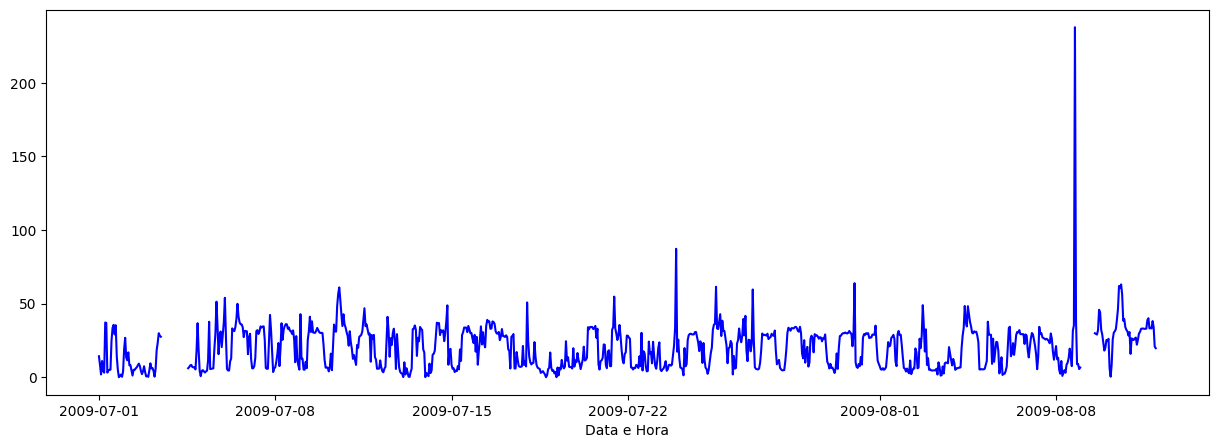

In [3]:
#Transforma a Coluna Data em DateTime
df['DateTime'] = pd.to_datetime(df['Data'])

#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Análise Gráfica dos Dados
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

In [4]:
#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone = df[:]
df_clone['Preco'] = df['Preco'] / df['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm = df_clone[['Preco']]

#Clona o DataFrame normalizado para um novo
df_lagged = df_norm[:]

#Determina os atrasos (em amostras)
lags = (1, 2, 3, 4, 5, 6)

#Gera o DataFrame com as Colunas de Atraso
df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for lag in lags for col in df_norm})

#Exclui valor NaN
df_proc = df_lagged.dropna()
df_proc

,Preco,Preco_t-1,Preco_t-2,Preco_t-3,Preco_t-4,Preco_t-5,Preco_t-6
DateTime,,,,,,,
2009-07-01 06:00:00,2.607719,0.216140,0.295439,0.771930,0.131930,0.591579,1.000000
2009-07-01 07:00:00,2.585965,2.607719,0.216140,0.295439,0.771930,0.131930,0.591579
2009-07-01 08:00:00,0.219649,2.585965,2.607719,0.216140,0.295439,0.771930,0.131930
2009-07-01 09:00:00,0.315789,0.219649,2.585965,2.607719,0.216140,0.295439,0.771930
2009-07-01 10:00:00,0.348772,0.315789,0.219649,2.585965,2.607719,0.216140,0.295439
...,...,...,...,...,...,...,...
2009-08-11 19:00:00,2.324211,2.353684,2.327719,2.812632,2.716491,2.312281,2.310877
2009-08-11 20:00:00,2.676491,2.324211,2.353684,2.327719,2.812632,2.716491,2.312281
2009-08-11 21:00:00,2.388772,2.676491,2.324211,2.353684,2.327719,2.812632,2.716491


In [5]:
#Calcula a Correlação de Pearson - Busca por uma Relação Linear
corr_p = df_proc.corr(method ='pearson')
corr_p

,Preco,Preco_t-1,Preco_t-2,Preco_t-3,Preco_t-4,Preco_t-5,Preco_t-6
Preco,1.000000,0.598839,0.441372,0.323220,0.248511,0.186620,0.173878
Preco_t-1,0.598839,1.000000,0.600391,0.442410,0.325006,0.252334,0.231727
Preco_t-2,0.441372,0.600391,1.000000,0.601011,0.443733,0.328736,0.307649
Preco_t-3,0.323220,0.442410,0.601011,1.000000,0.600975,0.445964,0.389233
Preco_t-4,0.248511,0.325006,0.443733,0.600975,1.000000,0.603158,0.522001
Preco_t-5,0.186620,0.252334,0.328736,0.445964,0.603158,1.000000,0.664975
Preco_t-6,0.173878,0.231727,0.307649,0.389233,0.522001,0.664975,1.000000


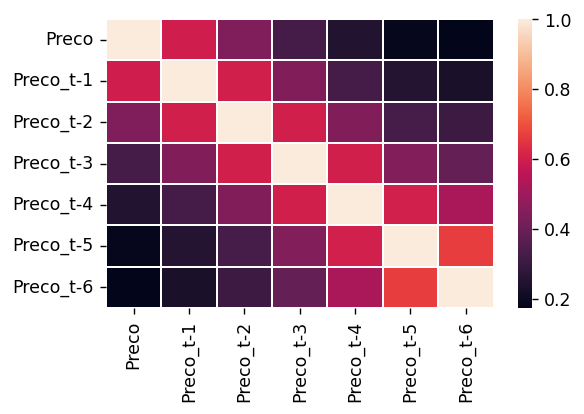

In [6]:
#Plota do Mapa de Calor da Correlação de Pearson
plt.figure(figsize=(5,3), dpi = 125)
sns.heatmap(corr_p, annot=False, fmt=".1f", linewidth=.1)
plt.show()

/tmp/ipykernel_556/1753068697.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  teste_ADF = adfuller(df_proc['Preco'].values)


ADF: -3.248381
p-valor: 0.017350


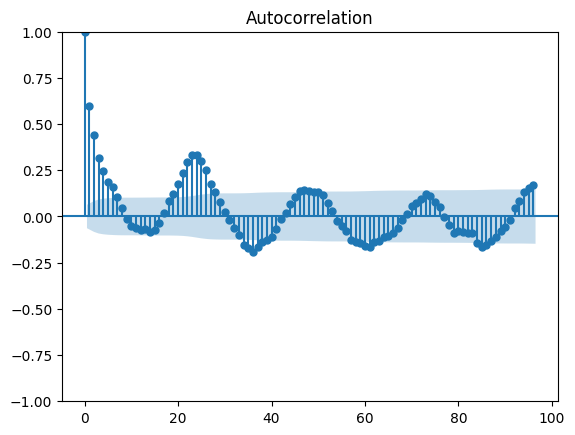

In [7]:
#Análise de Estacionariedade
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

teste_ADF = adfuller(df_proc['Preco'].values)
print('ADF: %f' % teste_ADF[0])
print('p-valor: %f' % teste_ADF[1]) # Se > 0.05 a série não é estacionária; Se <= 0.05 a série é estacionária

#Análise Gráfica de ACF - Serve somente para Séries Estacionárias
#A ideia desse teste é verificar se a previsão da série poderia ser feita com um modelo MA
#MA(q) --> q = quantidade de lags considerados fortes
sm.graphics.tsa.plot_acf(df_proc['Preco'].values, lags=96, alpha=0.05);

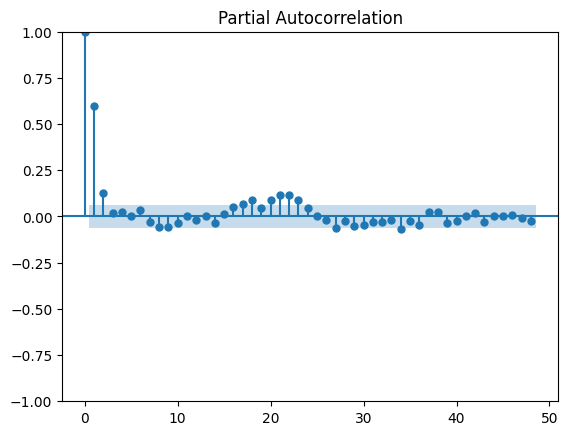

In [8]:
#Análise Gráfica de PACF - Serve somente para Séries Estacionárias
#A ideia desse teste é verificar se a previsão da série poderia ser feita com um modelo AR
#AR(p) --> p = quantidade de lags considerados fortes
sm.graphics.tsa.plot_pacf(df_proc['Preco'].values, lags=48, alpha=0.05, method="ols");

In [9]:
#Define as colunas que serão variáveis de entrada - explicativas
features1 = df_proc.columns[[1, 2, 3, 4, 5, 6]]
features2 = df_proc.columns[[1, 2]]
features3 = df_proc.columns[[1]]
print(features1)
print(features2)
print(features3)

Index(['Preco_t-1', 'Preco_t-2', 'Preco_t-3', 'Preco_t-4', 'Preco_t-5',
       'Preco_t-6'],
      dtype='object')
Index(['Preco_t-1', 'Preco_t-2'], dtype='object')
Index(['Preco_t-1'], dtype='object')


In [10]:
#Define a coluna que será variável de saída - interesse
target = df_proc.columns[[0]]
target

Index(['Preco'], dtype='object')

In [11]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste1 = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao1 = df_proc['2009-08-01 00:00:00':].index.values
df_dados_ajuste1 = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao1 = df_proc['2009-08-01 00:00:00':]

df_t_ajuste2 = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao2 = df_proc['2009-08-01 00:00:00':].index.values
df_dados_ajuste2 = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao2 = df_proc['2009-08-01 00:00:00':]

df_t_ajuste3 = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao3 = df_proc['2009-08-01 00:00:00':].index.values
df_dados_ajuste3 = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao3 = df_proc['2009-08-01 00:00:00':]

X_ajuste1 = df_dados_ajuste1[features1].values
Y_ajuste1 = df_dados_ajuste1[target].values
X_validacao1 = df_dados_validacao1[features1].values
Y_validacao1 = df_dados_validacao1[target].values

X_ajuste2 = df_dados_ajuste2[features2].values
Y_ajuste2 = df_dados_ajuste2[target].values
X_validacao2 = df_dados_validacao2[features2].values
Y_validacao2 = df_dados_validacao2[target].values

X_ajuste3 = df_dados_ajuste3[features3].values
Y_ajuste3 = df_dados_ajuste3[target].values
X_validacao3 = df_dados_validacao3[features3].values
Y_validacao3 = df_dados_validacao3[target].values

In [12]:
# Parametrização de Modelo de Regressão Linear
from sklearn.linear_model import LinearRegression

modelo_RL1 = LinearRegression().fit(X_ajuste1, Y_ajuste1)
modelo_RL2 = LinearRegression().fit(X_ajuste2, Y_ajuste2)
modelo_RL3 = LinearRegression().fit(X_ajuste3, Y_ajuste3)

In [26]:
df_previsto_RL1 = modelo_RL1.predict(X_validacao1)
df_previsto_RL1_denorm = df_previsto_RL1 * df['Preco'].iloc[0]

df_previsto_RL2 = modelo_RL2.predict(X_validacao2)
df_previsto_RL2_denorm = df_previsto_RL2 * df['Preco'].iloc[0]

df_previsto_RL3 = modelo_RL3.predict(X_validacao3)
df_previsto_RL3_denorm = df_previsto_RL3 * df['Preco'].iloc[0]

In [27]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error)

MAE1 = mean_absolute_error(y_true=Y_validacao1, y_pred=df_previsto_RL1_denorm)
MAE2 = mean_absolute_error(y_true=Y_validacao2, y_pred=df_previsto_RL2_denorm)
print(f"Modelo 1 - MAE: {MAE1.round(2)} // Modelo 2 - MAE: {MAE2.round(2)} // Modelo 3 - MAE: {MAE3.round(2)}")

MSE1 = mean_squared_error(y_true=Y_validacao1, y_pred=df_previsto_RL1_denorm)
MSE2 = mean_squared_error(y_true=Y_validacao2, y_pred=df_previsto_RL2_denorm)
print(f"Modelo 1 - MSE: {MSE1.round(2)} // Modelo 2 - MSE: {MSE2.round(2)} // Modelo 3 - MSE: {MSE3.round(2)}")
print(f"Modelo 1 - RMSE: {(MSE1**(1/2)).round(2)} // Modelo 2 - RMSE: {(MSE2**(1/2)).round(2)} // Modelo 3 - RMSE: {(MSE3**(1/2)).round(2)}")

r_sq1 = modelo_RL1.score(X_validacao1, Y_validacao1)
r_sq2 = modelo_RL2.score(X_validacao2, Y_validacao2)
print(f"Modelo 1 - R2: {r_sq1.round(2)} // Modelo 2 - R2: {r_sq2.round(2)} // Modelo 3 - R2: {r_sq3.round(2)}")

Modelo 1 - MAE: 19.37 // Modelo 2 - MAE: 19.36 // Modelo 3 - MAE: 19.31
Modelo 1 - RMSE: 23.03 // Modelo 2 - RMSE: 23.0 // Modelo 3 - RMSE: 23.13
Modelo 1 - R2: 0.17 // Modelo 2 - R2: 0.18 // Modelo 3 - R2: 0.15


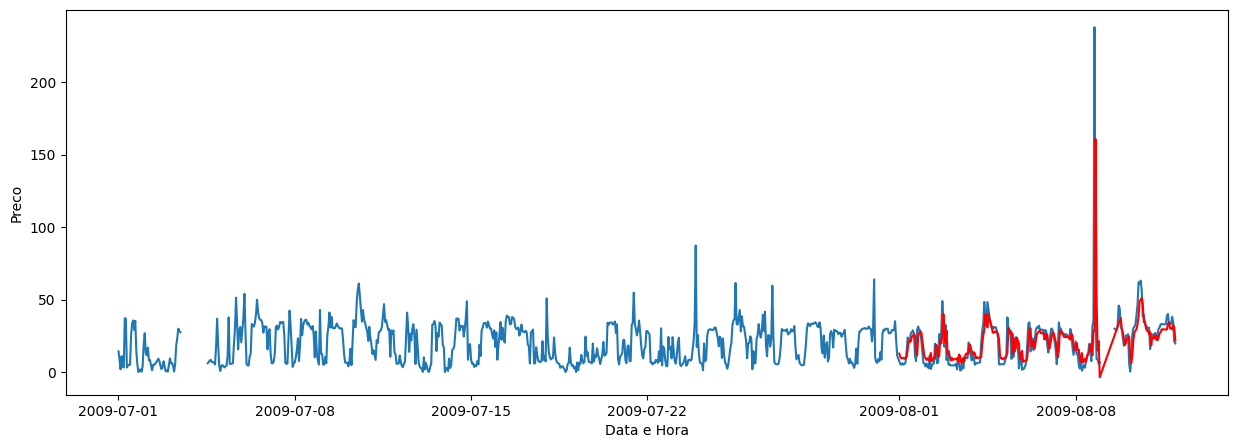

In [42]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_dados_validacao1.index, df_previsto_RL1_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()

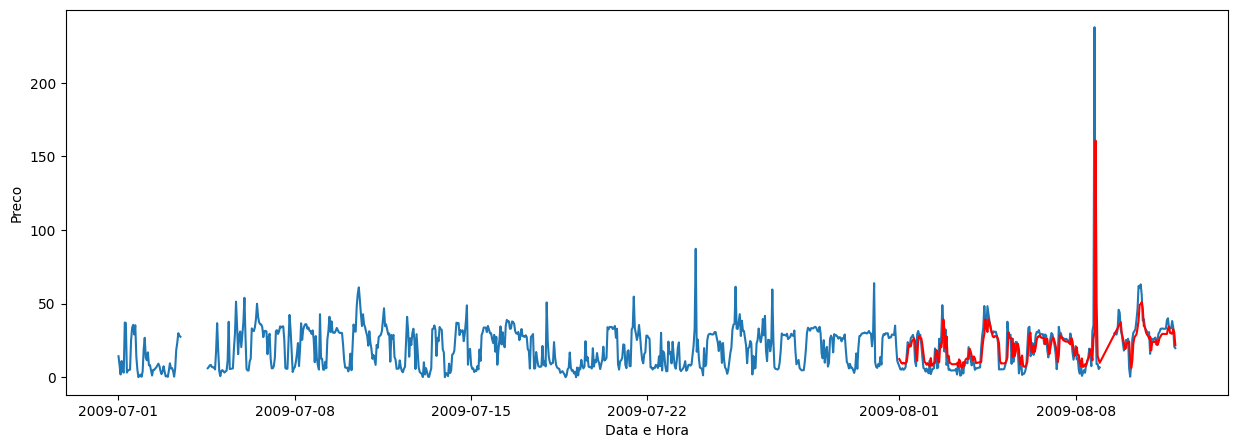

In [43]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_dados_validacao2.index, df_previsto_RL2_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()

In [46]:
# Parametrização de Modelo MA
from statsmodels.tsa.arima.model import ARIMA
MA_model3 = ARIMA(X_ajuste3, order=(0, 0, 5)) #order = (p,d,q)
MA_param3 = MA_model3.fit()

In [47]:
df_previsto = MA_param3.predict(start=len(X_validacao3), end=len(X_validacao3)+len(X_validacao3)-1)
df_previsto_denorm = df_previsto * df['Preco'].iloc[0]

In [48]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error)

MAE3 = mean_absolute_error(y_true=Y_validacao3, y_pred=df_previsto_denorm)
print(f"Modelo 3 - MAE: {round(MAE3, 2)}")

MSE3 = mean_squared_error(y_true=Y_validacao3, y_pred=df_previsto_denorm)
print(f"Modelo 3 - RMSE: {round((MSE3**(1/2)), 2)}")

r_sq3 = modelo_RL3.score(X_validacao3, Y_validacao3)
print(f"Modelo 3 - R2: {round(r_sq3, 2)}")

Modelo 3 - MAE: 17.04
Modelo 3 - RMSE: 18.85
Modelo 3 - R2: 0.15


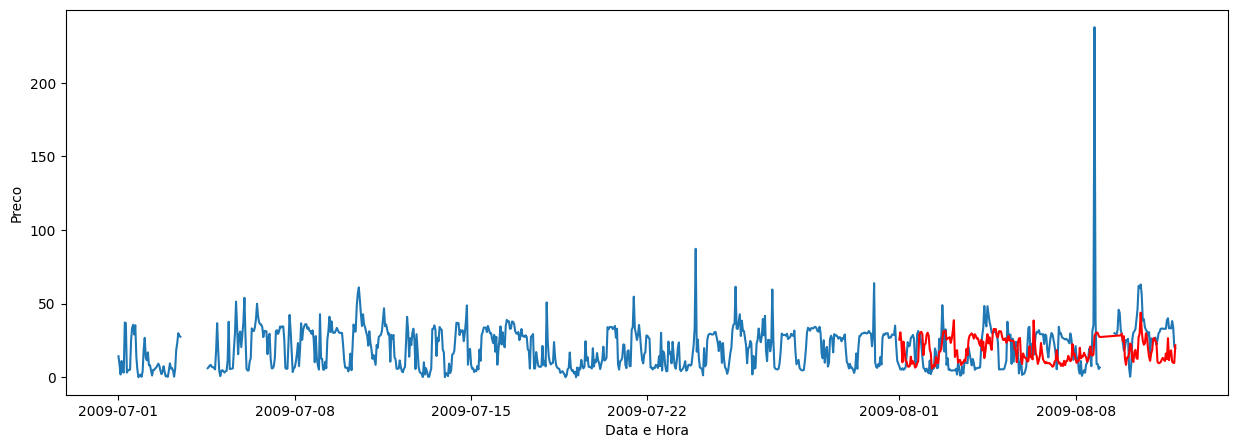

In [41]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_t_validacao3, df_previsto_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()